<div style="text-align: center; width: 100%;">
<h1 style="font-weight: 900; margin-bottom: 20px; text-align: center;"><b>FDR4VGT-CLOUD quick start</b></h1>
<img src="https://huggingface.co/front/assets/huggingface_logo-noborder.svg" alt="Hugging Face logo" style="width: 120px;">
</div>

This notebook loads the published cloud-detection model from Hugging Face and runs inference on a Proba-V sample scene.

## 1. Install dependencies

In [1]:
import sys
!{sys.executable} -m pip install mlstac==0.4.9 rasterio "torch>=2.7.0" "segmentation-models-pytorch>=0.5.0" matplotlib

## 2. Load the model

In [2]:
import mlstac

loader = mlstac.load(
    "https://huggingface.co/isp-uv-es/FDR4VGT-CLOUD/resolve/main/single/multisensor_single_1dpwdeeplabv3.json"
)
downloaded = loader.download(output_dir="fdr4vgt_model")
model = downloaded.compiled_model(device="cpu")
print("Model loaded.")

Model loaded.


## 3. Download the sample image

In [3]:
from huggingface_hub import hf_hub_download

sample_path = hf_hub_download(
    repo_id="isp-uv-es/ProbaV-SPOT",
    filename="PROBAV_L2A_20141111_184634_2_1KM_V201.tif",
    repo_type="dataset",
)
print("Sample image:", sample_path)

Sample image: /data/users/julio/.cache/huggingface/hub/datasets--isp-uv-es--ProbaV-SPOT/snapshots/9684db838d1f8ed9b288430bbefb11e2f1e683f8/PROBAV_L2A_20141111_184634_2_1KM_V201.tif


## 4. Read a 512x512 crop and run inference

In [4]:
import rasterio as rio
import torch

# Crop a 512 x 512 window with valid data and a mix of cloud and clear pixels.
window = rio.windows.Window(768, 1536, 512, 512)

with rio.open(sample_path) as src:
    image = src.read(window=window)

# Proba-V L2A radiometry stores bands as RED, NIR, BLUE, SWIR.
# Reorder to the model input: Blue, Red, NIR, SWIR.
image = image[[2, 0, 1, 3]]

image_t = torch.from_numpy(image).float().unsqueeze(0)

with torch.no_grad():
    prob = model(image_t)

print("Output shape:", prob.shape)
print("Probability range:", prob.min().item(), prob.max().item())

Output shape: torch.Size([1, 1, 512, 512])
Probability range: 1.0702718782340526e-06 0.9999973773956299


## 5. Plot the reflectance composite, cloud probability and binary mask

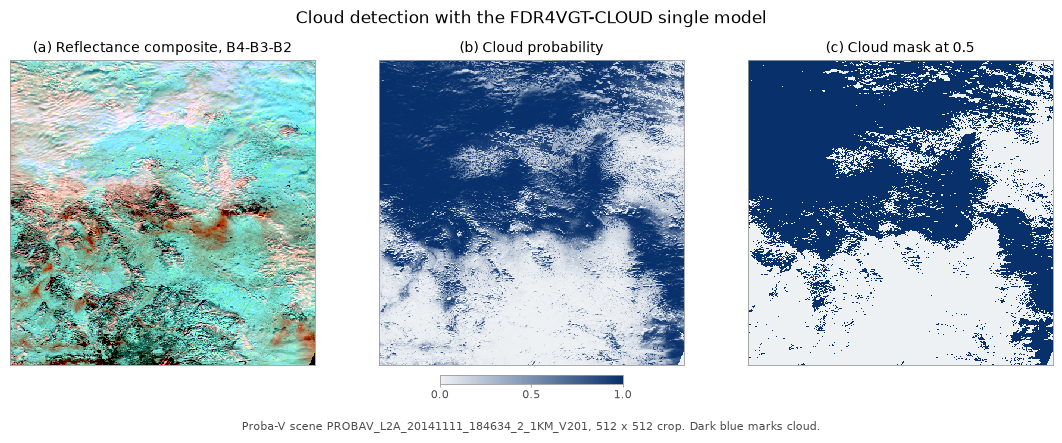

Cloud cover at 0.5: 0.515


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import FormatStrFormatter

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.edgecolor": "#9a9a9a",
    "axes.linewidth": 0.6,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})

prob_np = prob.squeeze().numpy()
mask = (prob_np > 0.5).astype(np.uint8)

def percentile_stretch(arr):
    """Percentile stretch per band over valid (positive) pixels."""
    out = np.zeros_like(arr, dtype=np.float32)
    for b in range(arr.shape[0]):
        values = arr[b][arr[b] > 0]
        if len(values) == 0:
            continue
        low, high = np.percentile(values, (2, 98))
        out[b] = np.clip((arr[b] - low) / max(high - low, 1e-6), 0, 1)
    return out

def srgb(values):
    """Apply sRGB gamma for a natural-looking display."""
    low = values <= 0.0031308
    return np.where(low, 12.92 * values, 1.055 * values ** (1 / 2.4) - 0.055)

# SWIR-NIR-Red composite printed as red-green-blue.
composite_bands = [3, 2, 1]
rgb = srgb(percentile_stretch(image[composite_bands]))
rgb = np.moveaxis(rgb, 0, -1)

prob_cmap = LinearSegmentedColormap.from_list("cloud", ["#eef1f4", "#08306b"])
mask_cmap = ListedColormap(["#eef1f4", "#08306b"])

fig = plt.figure(figsize=(11.2, 4.35))
grid = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.0, 1.0])

ax_rgb = fig.add_subplot(grid[0, 0])
ax_prob = fig.add_subplot(grid[0, 1])
ax_mask = fig.add_subplot(grid[0, 2])

ax_rgb.imshow(rgb, interpolation="nearest")
ax_rgb.set_title("(a) Reflectance composite, B4-B3-B2", pad=6)

im = ax_prob.imshow(prob_np, cmap=prob_cmap, vmin=0.0, vmax=1.0, interpolation="nearest")
ax_prob.set_title("(b) Cloud probability", pad=6)

ax_mask.imshow(mask, cmap=mask_cmap, vmin=0, vmax=1, interpolation="nearest")
ax_mask.set_title("(c) Cloud mask at 0.5", pad=6)

for ax in (ax_rgb, ax_prob, ax_mask):
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Cloud detection with the FDR4VGT-CLOUD single model", fontsize=12.5)
fig.supxlabel(
    "Proba-V scene PROBAV_L2A_20141111_184634_2_1KM_V201, 512 x 512 crop. Dark blue marks cloud.",
    fontsize=8,
    color="#4d4d4d",
)

fig.set_layout_engine("constrained", w_pad=0.32, h_pad=0.06)
fig.get_layout_engine().set(rect=(0.012, 0.040, 0.988, 0.972))
fig.draw_without_rendering()

margin_left = ax_rgb.get_position().x0
margin_right = 1.0 - ax_mask.get_position().x1
shift = 0.5 * (margin_right - margin_left)
for ax in (ax_rgb, ax_prob, ax_mask):
    box = ax.get_position()
    ax.set_position([box.x0 + shift, box.y0, box.width, box.height])
fig.set_layout_engine("none")

cax = ax_prob.inset_axes([0.20, -0.062, 0.60, 0.030])
cax.set_in_layout(False)
cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
cbar.set_ticks([0.0, 0.5, 1.0])
cbar.ax.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
cbar.ax.tick_params(
    labelsize=8, length=2, width=0.6, color="#9a9a9a", labelcolor="#4d4d4d", pad=2
)
cbar.outline.set_edgecolor("#9a9a9a")
cbar.outline.set_linewidth(0.6)

plt.show()
print(f"Cloud cover at 0.5: {mask.mean():.3f}")

## Next steps

- Try the full `predict_large` helper in `src/fdr4vgt_cloud/inference.py` for tiled inference on large rasters.
- Read `docs/model.md` for architecture details and `docs/dataset.md` for the data schema.